In [1]:
import os, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.analysis.data import *
from cifresignificative.viz.style import *
apply_style()
panel = load_panel()


# NUTS 2021 geography and spatial dependence in the regional screens
Two limits of the regional work (notebooks 25 and 34) are checked here. **(1) Region codes mix NUTS classifications** (France's 2013 regions, Greece's 2010 codes, Istat's ITD/ITE, the 2024 codes of Portugal and the Netherlands ...): the codes are translated to NUTS 2021 where a region was only renamed, never invented where it was split. **(2) Neighbouring regions are not independent:** the tests demean by country and permute within countries, which absorbs country clustering but not the similarity of neighbours.

**Design.** *Crosswalk* (`clean/nuts.py`): area overlap of each old region with the 2021 regions on the GISCO 20M boundaries (2010, 2013, 2016, 2021, 2024); a region is `nested` when at least 95% of its covered area lies in one 2021 region (renamed or merged), `split` otherwise (left out), `later` when the code exists only from 2024 (left out); NUTS 2006 codes are mapped by hand (`LEGACY_2006`). Where Eurostat publishes both the old and the new code of a region in the same year the native row is kept and the difference is reported. *Spatial structure* (`analysis/spatial.py`): queen contiguity within a country (islands linked to the nearest region of the country), Moran's I of the country-demeaned columns, and **eigenvector spatial filtering** (Griffith): each column is purged of the smooth spatial patterns, chosen greedily, that carry its autocorrelation. The notebook 34 EU-wide family is rerun plain and filtered (same pairs, within-country permutation p, BH over the family). *Calibration:* every x is replaced by independent spatially smooth noise (autocorrelation 0.4 and 0.8) while y stays real; a calibrated pipeline rejects about 5% and makes about 0 discoveries.

**Reading the filter.** Filtering removes spatial gradients shared by both variables, including a North-South gradient inside a country, which is the thing "why the South" asks about. A pair that survives is associated beyond smooth spatial patterns; a pair that does not may owe its association to such a pattern (or lose it by over-filtering): neither answer is "the" answer. Descriptive associations only.

In [2]:
from cifresignificative.analysis import experiments as ex, regional_south as rs
from cifresignificative.analysis.data import PROCESSED
nres = ex.run_nuts_all()
cw3, cov, ov, n4 = nres["n3_crosswalk"], nres["n1_coverage"], nres["n2_overlap"], nres["n4_south_geography"]
reg, reg21 = pd.read_parquet(PROCESSED / "regional.parquet"), pd.read_parquet(PROCESSED / "regional_nuts2021.parquet")
print("region codes in regional.parquet:", reg.geo.nunique(), "| NUTS 2021 regions after harmonising:", reg21.geo.nunique(), "| renamed rows:", int(reg21.geo_method.eq("renamed").sum()), "of", len(reg21))
print("codes in use that are not NUTS 2021 codes, by kind:", cw3.kind.value_counts().to_dict())
print("renamed or merged (carried over):", ", ".join(f"{o}>{n}" for o, n in zip(cw3[cw3.kind.isin(["nested", "legacy"])].old, cw3[cw3.kind.isin(["nested", "legacy"])].new)))
print("split, not allocated:", ", ".join(cw3[cw3.kind.eq("split")].old), "| exist only from 2024:", ", ".join(cw3[cw3.kind.eq("later")].old))
print("both codes published in the same year, relative difference of the two values:"); display(ov.round(4))
print("regions with data per window (mean over the 26 indicators):"); display(cov.groupby("window")[["regions_before", "regions_after"]].mean().round(1))

region codes in regional.parquet: 303 | NUTS 2021 regions after harmonising: 242 | renamed rows: 660 of 112435
codes in use that are not NUTS 2021 codes, by kind: {'nested': 46, 'legacy': 10, 'split': 7, 'later': 7}
renamed or merged (carried over): EL11>EL51, EL12>EL52, EL13>EL53, EL14>EL61, EL21>EL54, EL22>EL62, EL23>EL63, EL24>EL64, EL25>EL65, FI1A>FI1D, FR21>FRF2, FR22>FRE2, FR23>FRD2, FR24>FRB0, FR25>FRD1, FR26>FRC1, FR30>FRE1, FR41>FRF3, FR42>FRF1, FR43>FRC2, FR51>FRG0, FR52>FRH0, FR53>FRI3, FR61>FRI1, FR62>FRJ2, FR63>FRI2, FR71>FRK2, FR72>FRK1, FR81>FRJ1, FR82>FRL0, FR83>FRM0, FR91>FRY1, FR92>FRY2, FR93>FRY3, FR94>FRY4, FRA1>FRY1, FRA2>FRY2, FRA3>FRY3, FRA4>FRY4, FRA5>FRY5, ITD1>ITH1, ITD2>ITH2, ITD3>ITH3, ITD4>ITH4, ITD5>ITH5, ITE1>ITI1, ITE2>ITI2, ITE3>ITI3, ITE4>ITI4, PL11>PL71, PL31>PL81, PL32>PL82, PL33>PL72, PL34>PL84, SI01>SI03, SI02>SI04
split, not allocated: FI18, HR04, HU10, IE01, IE02, LT00, PL12 | exist only from 2024: NL35, NL36, PT19, PT1A, PT1B, PT1C, PT1D
both co

,indicator,pairs,median,p90,max
0,nuts2_physicians_per_100k,436,0.0024,0.0153,0.1452
1,nuts2_rd_pct_gdp,2,0.0073,0.0131,0.0146


regions with data per window (mean over the 26 indicators):


,regions_before,regions_after
window,,
early 2005-07,214.9,209.5
late 2021-23,225.7,219.7
recent 2015-19,236.6,228.2


In [3]:
# the "why the South" family on the original and on the NUTS 2021 geography
g = n4.groupby(["wave", "income_control"]).agg(tests=("rho_original", "size"), survivors_original=("significant_original", "sum"), survivors_nuts2021=("significant_nuts2021", "sum"), same_sign=("rho_original", lambda s: float((np.sign(s) == np.sign(n4.loc[s.index, "rho_nuts2021"])).mean())), max_abs_rho_change=("rho_original", lambda s: float((s - n4.loc[s.index, "rho_nuts2021"]).abs().max())))
display(g.round(3))
prim = n4[n4.wave.eq(rs.PRIMARY_WAVE) & ~n4.income_control]
print("primary wave: n of regions per pair, original vs NUTS 2021:", int(prim.n_original.median()), "vs", int(prim.n_nuts2021.median()), "| pairs whose survival flips:", int((prim.significant_original != prim.significant_nuts2021).sum()), "of", len(prim))

tests  survivors_original  survivors_nuts2021  same_sign  \
wave income_control                                                             
2010 False              40                  28                  29      1.000   
     True               40                  20                  20      0.975   
2013 False              40                  32                  32      1.000   
     True               40                  24                  24      1.000   
2017 False              40                  37                  37      1.000   
     True               40                  18                  18      1.000   
2021 False              40                  35                  35      1.000   
     True               40                  20                  20      1.000   

                     max_abs_rho_change  
wave income_control                      
2010 False                        0.090  
     True                         0.046  
2013 False                        0.088  
     True                         0.079  
2017 False                        0.024  
     True                         0.027  
2021 False                        0.012  
     True                         0.017

primary wave: n of regions per pair, original vs NUTS 2021: 181 vs 181 | pairs whose survival flips: 0 of 40


In [4]:
sres = ex.run_spatial_all()
m, fam, plc, nul = sres["sp1_moran"], sres["sp2_family"], sres["sp3_italy_rank"], sres["sp4_null"]
mp = m[m.wave.eq(rs.PRIMARY_WAVE) & ~m.income_control].set_index("indicator")
print("Moran's I of the country-demeaned columns (primary wave 2017, 2015-19 outcomes); z > 1.645 = positive spatial autocorrelation:")
display(mp[["n", "moran_i", "moran_z", "moran_i_filtered", "moran_z_filtered", "k_vectors"]].round(2))
print("columns with positive autocorrelation before / after filtering:", int((mp.moran_z > 1.645).sum()), "/", int((mp.moran_z_filtered > 1.645).sum()), "of", len(mp))

Moran's I of the country-demeaned columns (primary wave 2017, 2015-19 outcomes); z > 1.645 = positive spatial autocorrelation:


,n,moran_i,moran_z,moran_i_filtered,moran_z_filtered,k_vectors
indicator,,,,,,
arope,142,0.52,7.08,0.09,1.30,3
broadband_households_pct,158,0.25,3.68,0.10,1.57,1
coe_mio_eur,228,-0.04,-0.65,-0.04,-0.65,0
early_leavers_18_24,186,0.19,3.10,0.08,1.42,2
employment_rate_20_64,232,0.57,10.15,0.00,0.12,5
employment_rate_20_64_female,232,0.56,10.01,0.08,1.56,4
employment_rate_20_64_male,232,0.52,9.29,0.08,1.56,5
employment_rate_55_64,230,0.14,2.56,0.04,0.78,2
eqi,182,0.53,8.06,0.10,1.61,2


columns with positive autocorrelation before / after filtering: 27 / 0 of 40


In [5]:
s = fam.groupby(["wave", "income_control"]).agg(tests=("rho", "size"), survivors_plain=("significant", "sum"), survivors_filtered=("significant_filtered", "sum"), same_sign=("same_sign", "mean"))
display(s.round(2))
pf = fam[fam.primary & ~fam.income_control].copy(); pf["abs_rho"], pf["abs_rho_f"] = pf.rho.abs(), pf.rho_filtered.abs()
print("primary wave, plain survivors:", int(pf.significant.sum()), "| of them still significant after filtering:", int((pf.significant & pf.significant_filtered).sum()), "| filtered survivors that were not plain survivors:", int((~pf.significant & pf.significant_filtered).sum()))
print("median |rho|, plain vs filtered:", round(float(pf.abs_rho.median()), 3), "vs", round(float(pf.abs_rho_f.median()), 3), "| pairs with the sign changed:", int((~pf.same_sign).sum()))
print("survivors after filtering (primary wave, plain and beyond income):"); display(fam[fam.primary & fam.significant_filtered][["x", "y", "income_control", "n", "rho", "q_value", "rho_filtered", "q_value_filtered"]].round(3))

tests  survivors_plain  survivors_filtered  same_sign
wave income_control                                                       
2010 False              40               29                  12       0.80
     True               40               20                  22       0.90
2013 False              40               32                  25       0.88
     True               40               24                  27       0.82
2017 False              40               37                  15       0.88
     True               40               18                  23       0.75
2021 False              40               35                  15       0.85
     True               40               20                  20       0.72

primary wave, plain survivors: 37 | of them still significant after filtering: 14 | filtered survivors that were not plain survivors: 1
median |rho|, plain vs filtered: 0.316 vs 0.156 | pairs with the sign changed: 5
survivors after filtering (primary wave, plain and beyond income):


,x,y,income_control,n,rho,q_value,rho_filtered,q_value_filtered
176,eqi_impartiality,hours_per_inhabitant,False,177,0.237,0.005,0.179,0.048
177,eqi_impartiality,unemployment_rate,False,180,-0.324,0.001,-0.221,0.013
184,sbs_local_units_per_1000_inhabitants,employment_rate_20_64,False,195,0.475,0.001,0.525,0.002
185,sbs_local_units_per_1000_inhabitants,employment_rate_20_64_female,False,195,0.485,0.001,0.484,0.002
186,sbs_local_units_per_1000_inhabitants,gdp_per_hour_eur,False,191,0.470,0.001,0.473,0.002
187,sbs_local_units_per_1000_inhabitants,gdp_pps_pc_eu27,False,191,0.590,0.001,0.628,0.002
188,sbs_local_units_per_1000_inhabitants,hours_per_inhabitant,False,191,0.634,0.001,0.640,0.002
189,sbs_local_units_per_1000_inhabitants,unemployment_rate,False,194,-0.386,0.001,-0.465,0.002
191,sbs_manufacturing_employment_share_pct,employment_rate_20_64_female,False,188,0.036,0.654,-0.200,0.046
193,sbs_manufacturing_employment_share_pct,gdp_pps_pc_eu27,False,184,-0.170,0.026,-0.192,0.043


calibration with independent spatially smooth x (real y): mean over simulations


moran_i_of_x  share_p_below_005  discoveries  \
rho pipeline                                                 
0.4 filtered         0.157              0.065         0.06   
    plain            0.157              0.107         0.43   
0.8 filtered         0.566              0.066         0.11   
    plain            0.566              0.250         4.08   

              simulations_with_a_discovery  tests  
rho pipeline                                       
0.4 filtered                          0.03     40  
    plain                             0.11     40  
0.8 filtered                          0.04     40  
    plain                             0.51     40

Italy's rank among countries (p_rank = share of countries with a slope at least as far from the others, 1/n_countries is the minimum), plain vs spatially filtered:


,x,y,n_countries,slope_diff,p_rank,slope_diff_filtered,p_rank_filtered
34,sbs_local_units_per_1000_inhabitants,employment_rate_20_64_female,16,1.150,0.062,0.046,0.688
33,sbs_local_units_per_1000_inhabitants,employment_rate_20_64,16,0.953,0.062,0.037,0.625
28,sbs_manufacturing_employment_share_pct,employment_rate_20_64_female,16,0.697,0.062,0.103,0.750
37,sbs_wages_per_employee_keur,employment_rate_20_64,15,2.064,0.067,0.059,0.933
35,sbs_local_units_per_1000_inhabitants,unemployment_rate,15,-0.462,0.067,-0.139,0.133
38,sbs_wages_per_employee_keur,employment_rate_20_64_female,15,2.394,0.067,-0.332,0.800
27,sbs_manufacturing_employment_share_pct,employment_rate_20_64,16,0.628,0.125,0.142,0.625
26,sbs_manufacturing_employment_share_pct,hours_per_inhabitant,15,11.498,0.133,7.890,0.200
30,sbs_local_units_per_1000_inhabitants,gdp_pps_pc_eu27,15,424.592,0.200,393.036,0.200
39,sbs_wages_per_employee_keur,unemployment_rate,14,-0.983,0.214,-0.688,0.071


pairs with p_rank <= 0.10: plain 6 | filtered 1 of 40


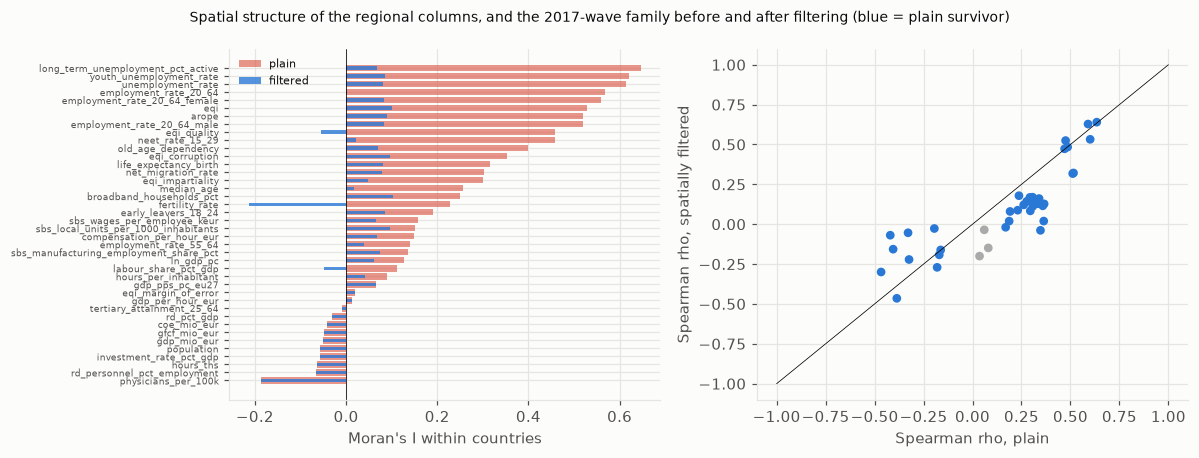

In [6]:
print("calibration with independent spatially smooth x (real y): mean over simulations"); 
display(nul.groupby(["rho", "pipeline"]).agg(moran_i_of_x=("moran_i_x", "mean"), share_p_below_005=("share_p_below_005", "mean"), discoveries=("discoveries", "mean"), simulations_with_a_discovery=("discoveries", lambda d: float((d > 0).mean())), tests=("n_tests", "first")).round(3))
print("Italy's rank among countries (p_rank = share of countries with a slope at least as far from the others, 1/n_countries is the minimum), plain vs spatially filtered:")
it = plc.sort_values("p_rank"); display(it[["x", "y", "n_countries", "slope_diff", "p_rank", "slope_diff_filtered", "p_rank_filtered"]].head(12).round(3))
print("pairs with p_rank <= 0.10: plain", int((plc.p_rank <= 0.10).sum()), "| filtered", int((plc.p_rank_filtered <= 0.10).sum()), "of", len(plc))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
d = mp.sort_values("moran_i"); axes[0].barh(range(len(d)), d.moran_i, color="#d94f3d", alpha=.6, label="plain"); axes[0].barh(range(len(d)), d.moran_i_filtered, color="#2a78d6", alpha=.8, height=.4, label="filtered")
axes[0].set_yticks(range(len(d))); axes[0].set_yticklabels(d.index, fontsize=6); axes[0].axvline(0, color="k", lw=.5); axes[0].set_xlabel("Moran's I within countries"); axes[0].legend(fontsize=7)
axes[1].scatter(pf.rho, pf.rho_filtered, s=22, c=np.where(pf.significant, "#2a78d6", "#aaaaaa")); axes[1].plot([-1, 1], [-1, 1], "k", lw=.5); axes[1].set_xlabel("Spearman rho, plain"); axes[1].set_ylabel("Spearman rho, spatially filtered")
fig.suptitle("Spatial structure of the regional columns, and the 2017-wave family before and after filtering (blue = plain survivor)", fontsize=9); plt.tight_layout(); plt.show()

## The notebook 25 screens on the NUTS 2021 geography, with and without spatial filtering
Notebook 25 screened every pair of regional indicators within countries (levels 2015-19, and changes between 2005-09 and 2015-19) with Benjamini-Hochberg control over all pairs; R2b replaced the asymptotic p by the within-country permutation p. The same two pair screens (`regional_south.screen_perm`, size-scaled columns and mechanical pairs excluded as before) are rerun here on (a) the original region codes, (b) the NUTS 2021 geography and (c) the NUTS 2021 geography after spatial filtering of every column. Calibration of the whole screen: columns shuffled within countries, and every column replaced by independent spatially smooth noise (autocorrelation 0.4 and 0.8, Moran's I of about 0.16 and 0.57), plain against filtered; the BH discoveries per screen should be about zero.

In [7]:
scr = ex.run_spatial_screens(n_sim=30)
cnt, prs, nul = scr["sp6_screen_counts"].set_index("screen"), scr["sp5_screen_pairs"], scr["sp7_screen_null"]
print("pairs tested and BH survivors (within-country permutation p):"); display(cnt.T)
for name in ("levels", "changes"):
    x = prs[prs.screen.eq(name)]
    lost = x[x.significant & ~x.significant_filtered.fillna(False)]; gain = x[~x.significant.fillna(False) & x.significant_filtered.fillna(False)]; kept = x[x.significant & x.significant_filtered.fillna(False)]
    print(f"{name}: survivors on NUTS 2021 {int(x.significant.sum())}, kept after filtering {len(kept)}, lost {len(lost)}, new {len(gain)} | median |rho| of the lost {lost.rho.abs().median():.2f}, of all plain survivors {x[x.significant].rho.abs().median():.2f}, of the kept after filtering {kept.rho_filtered.abs().median():.2f} | kept pairs whose sign changed: {int((~kept.same_sign).sum())}")
    display(lost.sort_values("rho", key=abs, ascending=False)[["x", "y", "rho", "rho_filtered", "q_value", "q_value_filtered"]].head(6).round(3))
print("null of the whole screen (BH discoveries per simulation; share of tests with p < 0.05):")
display(nul.groupby(["screen", "null", "pipeline"]).agg(mean_discoveries=("discoveries", "mean"), simulations_with_a_discovery=("discoveries", lambda d: float((d > 0).mean())), share_p_below_005=("share_p_below_005", "mean"), tests=("n_tests", "first")).round(3))

pairs tested and BH survivors (within-country permutation p):


screen,levels,changes
pairs_original,284,260
significant_original,164,53
pairs_nuts2021,284,260
significant_nuts2021,169,57
pairs_filtered,284,260
significant_filtered,159,46
both_nuts2021_and_filtered,152,44
sign_changed,20,24
columns_with_positive_autocorrelation,17,10
columns_after_filter,0,0


levels: survivors on NUTS 2021 169, kept after filtering 152, lost 17, new 7 | median |rho| of the lost 0.18, of all plain survivors 0.36, of the kept after filtering 0.32 | kept pairs whose sign changed: 0


,x,y,rho,rho_filtered,q_value,q_value_filtered
46,broadband_households_pct,youth_unemployment_rate,-0.345,-0.170,0.000,0.094
130,employment_rate_20_64_male,old_age_dependency,0.257,0.087,0.001,0.283
28,broadband_households_pct,employment_rate_20_64_male,0.248,0.170,0.007,0.072
38,broadband_households_pct,neet_rate_15_29,-0.247,-0.172,0.011,0.093
114,employment_rate_20_64_female,physicians_per_100k,-0.238,-0.166,0.004,0.063
211,labour_share_pct_gdp,old_age_dependency,-0.225,-0.086,0.002,0.279


changes: survivors on NUTS 2021 57, kept after filtering 44, lost 13, new 2 | median |rho| of the lost 0.25, of all plain survivors 0.35, of the kept after filtering 0.40 | kept pairs whose sign changed: 0


,x,y,rho,rho_filtered,q_value,q_value_filtered
384,employment_rate_20_64_male,labour_share_pct_gdp,0.348,0.192,0.000,0.056
401,employment_rate_55_64,labour_share_pct_gdp,0.337,0.185,0.000,0.078
467,labour_share_pct_gdp,long_term_unemployment_pct_active,-0.313,-0.170,0.001,0.146
527,old_age_dependency,unemployment_rate,-0.300,-0.196,0.001,0.056
356,employment_rate_20_64,old_age_dependency,0.281,0.186,0.001,0.068
329,early_leavers_18_24,fertility_rate,0.278,0.168,0.006,0.162


null of the whole screen (BH discoveries per simulation; share of tests with p < 0.05):


mean_discoveries  \
screen  null                      pipeline                     
changes shuffled within countries filtered             0.000   
                                  plain                0.000   
        smooth noise 0.4          filtered             0.000   
                                  plain                0.000   
        smooth noise 0.8          filtered             0.000   
                                  plain               12.733   
levels  shuffled within countries filtered             0.000   
                                  plain                0.000   
        smooth noise 0.4          filtered             0.000   
                                  plain                0.000   
        smooth noise 0.8          filtered             0.000   
                                  plain               16.933   

                                            simulations_with_a_discovery  \
screen  null                      pipeline                                 
changes shuffled within countries filtered                           0.0   
                                  plain                              0.0   
        smooth noise 0.4          filtered                           0.0   
                                  plain                              0.0   
        smooth noise 0.8          filtered                           0.0   
                                  plain                              0.7   
levels  shuffled within countries filtered                           0.0   
                                  plain                              0.0   
        smooth noise 0.4          filtered                           0.0   
                                  plain                              0.0   
        smooth noise 0.8          filtered                           0.0   
                                  plain                              0.9   

                                            share_p_below_005  tests  
screen  null                      pipeline                            
changes shuffled within countries filtered              0.048    259  
                                  plain                 0.048    259  
        smooth noise 0.4          filtered              0.059    260  
                                  plain                 0.068    260  
        smooth noise 0.8          filtered              0.072    260  
                                  plain                 0.231    260  
levels  shuffled within countries filtered              0.052    284  
                                  plain                 0.052    284  
        smooth noise 0.4          filtered              0.059    284  
                                  plain                 0.078    284  
        smooth noise 0.8          filtered              0.076    284  
                                  plain                 0.238    284

## Takeaways (NUTS 2021 geography and spatial dependence; notebook 34 family; descriptive)
- **Harmonising the codes changes almost nothing, and it is not a coverage fix.** 303 region codes become 242 NUTS 2021 regions: 56 old codes are carried over by a rename (46 by area overlap, 10 NUTS 2006 codes by hand: Istat's ITD/ITE and FI1A), 7 are splits left out (FI18, HR04, HU10, IE01, IE02, LT00, PL12) and 7 exist only from the 2024 classification (NL35, NL36, PT19, PT1A-D). 660 of 112,435 rows are renamed. France 2016 and Greece 2013 are pure relabelling, so no value is summed or allocated. Where Eurostat publishes both codes in the same year the values agree closely (physicians: median difference 0.24% over 436 pairs, 90th percentile 1.5%, maximum 14.5%; R&D: 2 pairs). The number of regions with data per window does not rise (2015-19: 236.6 codes before, 228.2 after, because the split and post-2021 codes drop out).
- **Notebook 34's EU-wide result does not depend on the code mix.** Survivors of the false-discovery cut are the same in every wave and variant except one extra survivor in the 2010 wave without income control (28 against 29); no pair flips in the primary wave (0 of 40), the sign agrees everywhere but one pair (2010, beyond income), and the largest change in rho is 0.09.
- **The regional columns are spatially autocorrelated, strongly for labour-market and governance variables.** Moran's I of the country-demeaned columns (2017 wave): long-term unemployment 0.65, youth unemployment 0.62, unemployment 0.61, employment 0.57, EQI 0.53, AROPE 0.52; the structural business statistics 0.14-0.16; GDP per head only 0.06 (z 1.2). 27 of 40 columns have a clearly positive I; after filtering none do (1-5 eigenvectors per column; 13 columns needed none). Two columns are negatively autocorrelated (physicians per 100,000, I -0.19; and fertility after filtering, -0.21): not addressed.
- **The within-country permutation test over-rejects under spatial autocorrelation; the filtered pipeline is close to calibrated.** With independent spatially smooth x and real y, the plain pipeline gives p < 0.05 in 10.7% of tests when x has Moran's I 0.16 (0.43 false discoveries per family, a discovery in 11% of simulations) and in 25.0% when I is 0.57 (4.08 discoveries per family, a discovery in 51% of simulations); the filtered pipeline gives 6.5% and 6.6% (0.06 and 0.11 discoveries, a discovery in 3-4% of simulations). Nominal level: 5% and about 0.
- **Filtering halves the primary-wave family without income control and leaves the beyond-income one intact.** 2017 wave, plain against filtered survivors: 37 against 15 without the income control (14 of the 37 stay, one pair is new: manufacturing share against female employment), 18 against 23 beyond income; the other waves 29/12, 32/25, 35/15 without and 20/22, 24/27, 20/20 beyond income (2010, 2013, 2021). Median |rho| falls from 0.316 to 0.156 and 5 pairs change sign. What stays without the income control in 2017: local units per 1,000 inhabitants against both employment rates, unemployment, GDP per head, output per hour and hours per inhabitant (rho 0.47-0.64, similar to or larger than the plain values), pay per employee against employment, unemployment and hours (smaller: 0.32 instead of 0.52 for employment), and EQI impartiality against unemployment and hours; **no other EQI pair survives, so the plain EQI-employment associations of notebook 34 are partly a spatial pattern**. Beyond income the EQI components survive against employment and unemployment (|rho| 0.18-0.35, mostly about half the plain values); a few beyond-income pairs change sign (EQI against GDP per head: 0.02 plain, -0.19 filtered), so treat them as fragile.
- **Italy's steep slopes do not survive filtering.** In notebook 34, 6 of 40 EU-wide pairs had Italy's slope among the most extreme of 14-16 countries (p_rank 0.062-0.067, the smallest possible value is 1/n). After filtering the columns, their ranks are 0.13-0.93 and only one pair of the whole family has p_rank <= 0.10 (pay per employee against unemployment, 0.071, which was 0.21 before). The Italian steepness is mostly the North-South gradient that both variables share, which is what the filter removes.
- **The notebook 25 screens survive spatial filtering.** On the original region codes the screens give the notebook 25 counts (164 of 284 pairs for the levels, 53 of 260 for the changes); on the NUTS 2021 geography 169 and 57; after spatial filtering of every column 159 and 46, with 152 and 44 pairs in both lists (17 and 13 lost, 7 and 2 new). The pairs lost are the weak ones (median |rho| 0.18 and 0.25 against 0.36 and 0.35 for all survivors) and involve broadband, old-age dependency and the labour share; no pair that stays changes sign (median |rho| of the kept pairs after filtering: 0.32 and 0.40). So the within-country associations of notebook 25 are not an artefact of the code mix or of neighbouring regions moving together. Spatial autocorrelation is nonetheless real in the columns (17 of 30 level columns and 10 of 29 change columns have a clearly positive Moran's I, none after filtering).
- **The whole-screen calibration depends on how smooth the noise is.** With columns shuffled within countries both screens give 0 discoveries. With independent spatially smooth noise of autocorrelation 0.4 (Moran's I about 0.16) the plain screen gives 0 discoveries (6.8-7.8% of tests at p < 0.05, filtered 5.9%); at 0.8 (Moran's I about 0.57, like the labour-market and governance columns) the plain screen makes 16.9 false discoveries per simulation for the levels (a discovery in 90% of 30 simulations) and 12.7 for the changes (70%), while the filtered screen makes none (7.6% and 7.2% of tests at p < 0.05, against 23-24% for the plain one). The real columns have a mix of the two regimes, which is why the plain survivors are mostly (not entirely) real.
- **How to read the filter.** It removes smooth spatial patterns, including a North-South gradient inside Italy, which is also what "why the South" asks about: a pair that survives is associated beyond such a pattern, a pair that does not may be explained by it or over-filtered. The 2017 family is therefore reported both ways and the plain test should be read as liberal for the autocorrelated columns.
- **Limits.** Boundaries are generalised (20M) and neighbours are same-country only (cross-border links ignored), the number of eigenvectors comes from a greedy rule with an analytic z-threshold (1.645), the filter is applied to each column separately, the area crosswalk is a proxy for population overlap and splits are not allocated, Germany and Belgium are absent from EQI, and the Italy-only track (21 regions) is not filtered because it has too few observations to spend degrees of freedom on eigenvectors. The calibration uses a first-order autoregressive pattern, not the real geography of the missingness. All associations are descriptive.
